# PreTest 04: Unsupervised Learning — การแบ่งกลุ่มลูกค้า (Customer Segmentation)
### K-Means · Hierarchical Clustering · DBSCAN · PCA · Elbow / Silhouette / Davies-Bouldin

> **ที่มา:** ดัดแปลงและขยายจาก Kaggle Notebook
> [Customer Segmentation (K-Means) | Analysis](https://www.kaggle.com/code/kushal1996/customer-segmentation-k-means-analysis) โดย Kushal
> สิ่งที่เพิ่ม: คำอธิบายภาษาไทย, Scaling, Silhouette/Davies-Bouldin, Hierarchical, DBSCAN, PCA, การตีความเป็น Persona
>
> **ชุดข้อมูล (Dataset):** [Mall Customer Segmentation Data](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) — ลูกค้าห้าง 200 คน

---

## Supervised Learning เทียบกับ Unsupervised Learning

| | Supervised (PreTest 01–03) | **Unsupervised (บทนี้)** |
|---|---|---|
| มีคำตอบ (y) หรือไม่ | มี | **ไม่มี** |
| เป้าหมาย | ทำนายคำตอบ | **หาโครงสร้าง/กลุ่มที่ซ่อนอยู่** |
| Train/Test Split | ต้องมี | ไม่จำเป็น (ไม่มีคำตอบให้เทียบ) |
| วัดผลด้วย | Accuracy, F1, R² ... | **Inertia, Silhouette, Davies-Bouldin** + **ความหมายทางธุรกิจ** |

## ขั้นตอน
1 โจทย์ → 2 โหลด → 3 สำรวจ → 4 Cleaning → 5 EDA → 6 เลือก Feature + Scale → 7 K-Means → 8 Hierarchical → 9 DBSCAN → 10 เปรียบเทียบ → 11 PCA (3 Feature) → 12 Persona และข้อเสนอแนะ

---
# ขั้นที่ 1: กำหนดโจทย์
- **เป้าหมาย:** แบ่งลูกค้าเป็นกลุ่มที่มีพฤติกรรมคล้ายกัน เพื่อให้ฝ่ายการตลาดทำโปรโมชันเฉพาะกลุ่ม
- **ประเภทปัญหา:** ไม่มีคอลัมน์คำตอบ → **Clustering (Unsupervised)**
- **วัดผลด้วย:**

| Metric | ความหมาย | ดีเมื่อ |
|---|---|---|
| **Inertia** (WCSS) | ผลรวมระยะ² จากจุดถึงจุดศูนย์กลางกลุ่ม (กลุ่มแน่นเพียงใด) | ต่ำ (แต่ลดลงเสมอเมื่อเพิ่ม k → ใช้ Elbow) |
| **Silhouette Score** | จุดอยู่ใกล้กลุ่มตัวเองมากกว่ากลุ่มอื่นเพียงใด (−1 ถึง 1) | **สูง** (> 0.5 ถือว่าดี) |
| **Davies-Bouldin Index** | ความคล้ายระหว่างกลุ่ม (กลุ่มแยกกันชัดเพียงใด) | **ต่ำ** |

# ขั้นที่ 2: นำเข้าไลบรารีและโหลดข้อมูล

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [2]:
DATA_FILE = "Data/Mall_Customers.csv"
if not os.path.exists(DATA_FILE):
    import kagglehub   # ถ้า error ให้รัน !pip install kagglehub
    DATA_FILE = os.path.join(kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python"), "Mall_Customers.csv")

df = pd.read_csv(DATA_FILE)
print("ขนาดข้อมูล:", df.shape)
df.head()

ขนาดข้อมูล: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


---
# ขั้นที่ 3: สำรวจข้อมูลเบื้องต้น

| คอลัมน์ | ความหมาย |
|---|---|
| `CustomerID` | รหัสลูกค้า (ไม่ใช้ในการจัดกลุ่ม) |
| `Gender` | เพศ |
| `Age` | อายุ |
| `Annual Income (k$)` | รายได้ต่อปี (พันดอลลาร์) |
| `Spending Score (1-100)` | คะแนนการใช้จ่ายที่ห้างให้ (ยิ่งสูง ยิ่งใช้จ่ายมาก/บ่อย) |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.describe().round(1)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


---
# ขั้นที่ 4: ทำความสะอาดข้อมูล

In [5]:
print("ค่าหาย:\n", df.isnull().sum())
print("\nแถวซ้ำ:", df.duplicated().sum())

# เปลี่ยนชื่อคอลัมน์ให้สั้นลง ใช้งานง่าย
df = df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'})
df = df.drop(columns='CustomerID')      # รหัสลูกค้าไม่มีความหมายต่อพฤติกรรม
df.head()

ค่าหาย:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

แถวซ้ำ: 0


,Gender,Age,Income,Spending
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


> **ผลลัพธ์:** ข้อมูลสะอาด ไม่มีค่าหาย ไม่มีแถวซ้ำ — ลบ `CustomerID` เพราะหากนำมาใช้ โมเดลจะจัดกลุ่มตามเลขรหัส ซึ่งไม่มีความหมาย

---
# ขั้นที่ 5: EDA & Visualization

### 5.1 การกระจายของแต่ละตัวแปร

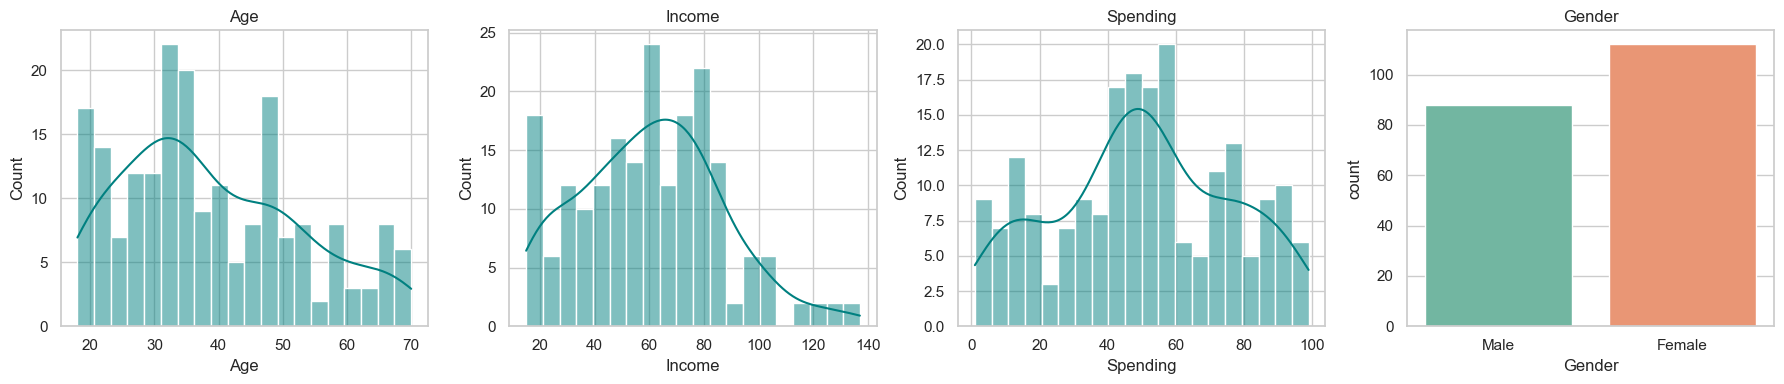

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes[:3], ['Age', 'Income', 'Spending']):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color='teal'); ax.set_title(col)
sns.countplot(x='Gender', data=df, ax=axes[3], palette='Set2', hue='Gender', legend=False); axes[3].set_title('Gender')
plt.tight_layout(); plt.show()

### 5.2 ความสัมพันธ์ระหว่างตัวแปร

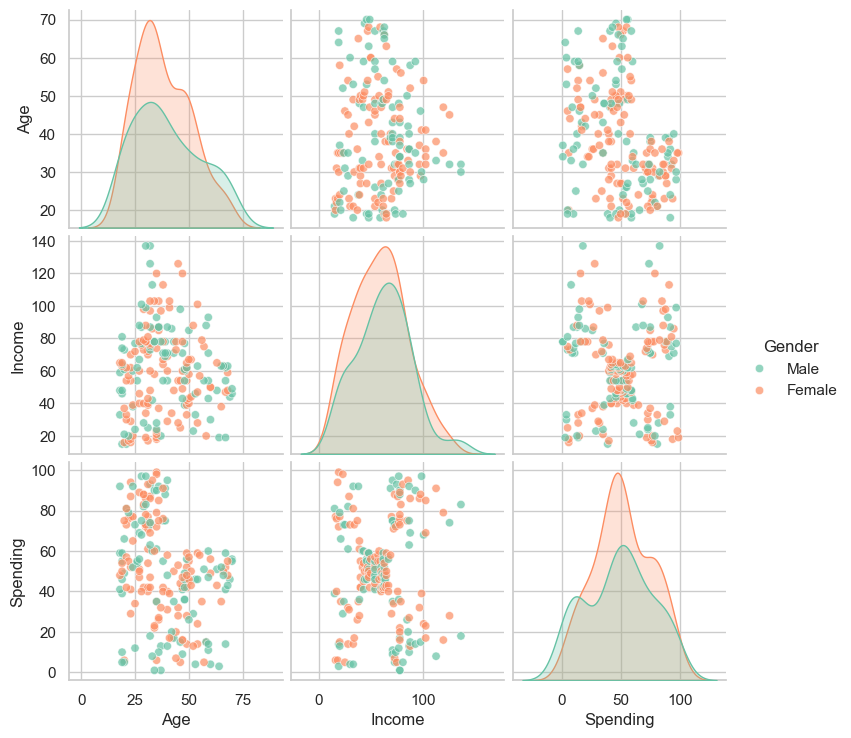

In [7]:
sns.pairplot(df, hue='Gender', palette='Set2', plot_kws={'alpha': 0.7})
plt.show()

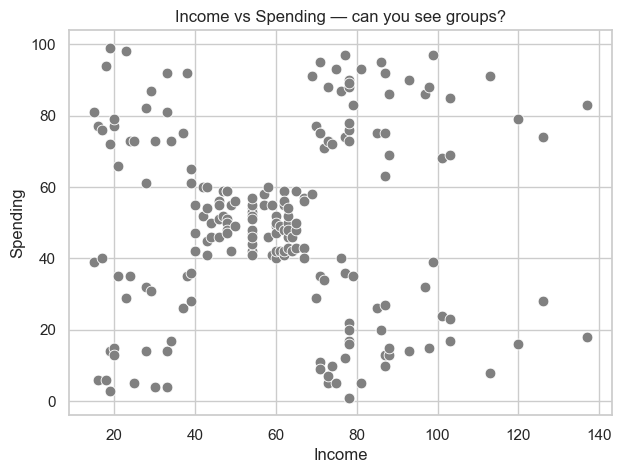

In [8]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='Income', y='Spending', data=df, s=60, color='gray')
plt.title('Income vs Spending — can you see groups?')
plt.show()

> **Insight:** กราฟ Income vs Spending สามารถสังเกตเห็นได้ **5 กลุ่ม** (มุมทั้ง 4 + ตรงกลาง)
> - Age vs Spending: คนอายุ > 40 แทบไม่มีใครใช้จ่ายสูงมาก
> - Gender กระจายปนกันทุกกราฟ → **เพศไม่ช่วยแบ่งกลุ่ม** จึงไม่ใช้

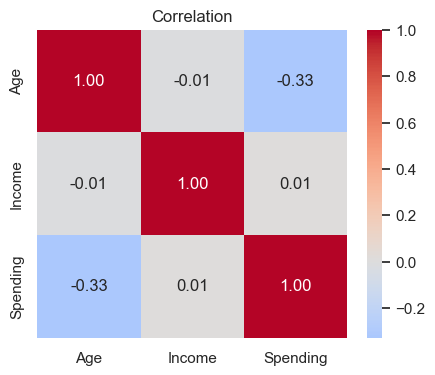

In [9]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[['Age', 'Income', 'Spending']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation'); plt.show()

---
# ขั้นที่ 6: เลือก Feature และ Scale

- **Feature หลัก:** `Income` + `Spending` (2 มิติ → วาดกราฟดูผลได้ง่าย ตรงกับโจทย์การตลาด)
- **ต้อง Scale:** ทุกวิธีในบทนี้ใช้ **ระยะทาง** ถ้าตัวแปรมีช่วงต่างกัน ตัวที่ช่วงกว้างจะครอบงำ

In [10]:
from sklearn.preprocessing import StandardScaler

features = ['Income', 'Spending']
scaler = StandardScaler()
X = scaler.fit_transform(df[features])
pd.DataFrame(X, columns=features).describe().loc[['mean', 'std']].round(2)

,Income,Spending
mean,-0.0,-0.0
std,1.0,1.0


---
# ขั้นที่ 7: โมเดลที่ 1 — K-Means

### หลักการ
1. สุ่มวางจุดศูนย์กลาง (Centroid) k จุด
2. ให้ทุกจุดข้อมูลเข้ากลุ่มของ Centroid ที่ใกล้ที่สุด
3. ย้าย Centroid ไปที่ค่าเฉลี่ยของสมาชิกในกลุ่ม
4. ทำข้อ 2–3 ซ้ำจนไม่เปลี่ยน

**ต้องกำหนด k เอง** → ใช้ Elbow + Silhouette ช่วยตัดสินใจ

### 7.1 เลือกจำนวนกลุ่ม (k)

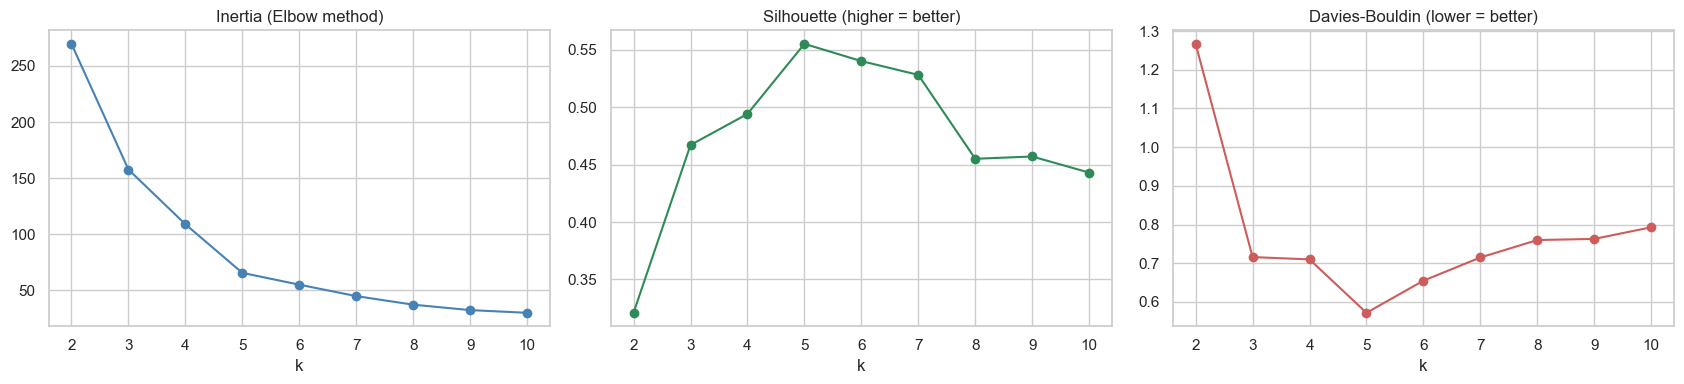

,Inertia,Silhouette,Davies-Bouldin
k,,,
2,269.691,0.321,1.267
3,157.704,0.467,0.716
4,108.921,0.494,0.710
5,65.568,0.555,0.572
6,55.057,0.540,0.655
7,44.865,0.528,0.715
8,37.228,0.455,0.760
9,32.392,0.457,0.763
10,29.982,0.443,0.793


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({'k': k, 'Inertia': km.inertia_,
                 'Silhouette': silhouette_score(X, km.labels_),
                 'Davies-Bouldin': davies_bouldin_score(X, km.labels_)})
k_df = pd.DataFrame(rows).set_index('k').round(3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col, color in zip(axes, k_df.columns, ['steelblue', 'seagreen', 'indianred']):
    ax.plot(k_df.index, k_df[col], 'o-', color=color); ax.set_title(col); ax.set_xlabel('k')
axes[0].set_title('Inertia (Elbow method)'); axes[1].set_title('Silhouette (higher = better)')
axes[2].set_title('Davies-Bouldin (lower = better)')
plt.tight_layout(); plt.show()
k_df

> **Elbow:** Inertia ลดลงเร็วจนถึง k = 5 แล้วจึงลดช้าลง (ข้อศอกอยู่ที่ 5)
> **Silhouette สูงสุด** และ **Davies-Bouldin ต่ำสุด** ที่ k = 5 เช่นกัน → ทั้ง 3 วิธีตรงกัน และสอดคล้องกับที่สังเกตได้จากกราฟในขั้นที่ 5 → เลือก **k = 5**

### 7.2 เทรน K-Means (k = 5) และดูผล

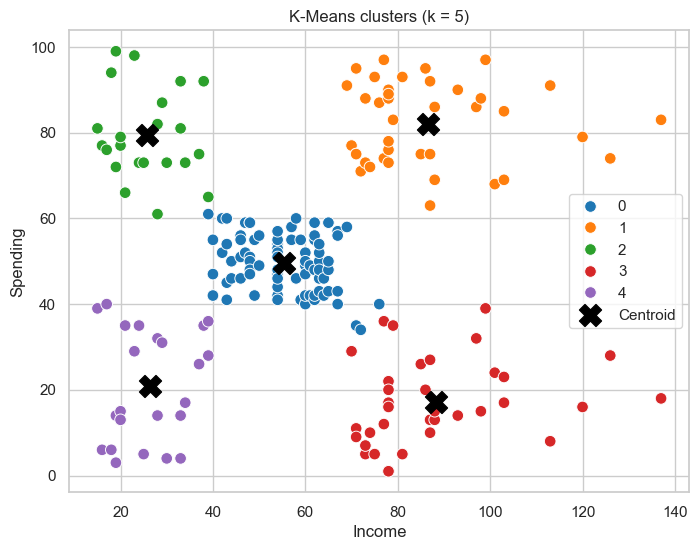

Silhouette = 0.555   Davies-Bouldin = 0.572


In [12]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X)
df['KMeans'] = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)      # แปลง Centroid กลับเป็นหน่วยจริง

plt.figure(figsize=(8, 6))
sns.scatterplot(x='Income', y='Spending', hue='KMeans', data=df, palette='tab10', s=70)
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=250, marker='X', label='Centroid')
plt.title('K-Means clusters (k = 5)'); plt.legend(); plt.show()

print(f"Silhouette = {silhouette_score(X, kmeans.labels_):.3f}   Davies-Bouldin = {davies_bouldin_score(X, kmeans.labels_):.3f}")

### 7.3 Profile ของแต่ละกลุ่ม

In [13]:
profile = df.groupby('KMeans').agg(Customers=('Income', 'size'), Age=('Age', 'mean'),
                                   Income=('Income', 'mean'), Spending=('Spending', 'mean'),
                                   Female_pct=('Gender', lambda s: (s == 'Female').mean() * 100)).round(1)
profile.sort_values('Income')

,Customers,Age,Income,Spending,Female_pct
KMeans,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


### 7.4 การวิเคราะห์ผล K-Means

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ควรแบ่งกี่กลุ่ม? | Elbow, Silhouette, Davies-Bouldin ชี้ **k = 5** ตรงกันทั้ง 3 วิธี | มั่นใจได้ และสอดคล้องกับที่สังเกตได้จากกราฟ 5.2 |
| กลุ่มแยกชัดหรือไม่ | Silhouette **0.555** (> 0.5) | ดี — ลูกค้าแต่ละคนใกล้กลุ่มตัวเองมากกว่ากลุ่มอื่นชัดเจน |
| กลุ่มปนกันหรือไม่ | Davies-Bouldin **0.572** (ต่ำสุดในทุก k) | กลุ่มแยกกันดี |
| แต่ละกลุ่มเป็นอย่างไร? | 5 กลุ่ม = มุมทั้ง 4 ของกราฟ (รายได้ต่ำ/สูง × ใช้จ่ายต่ำ/สูง) + กลุ่มกลาง | กลุ่มกลางใหญ่ที่สุด **81 คน (40%)** |
| เพศมีผลหรือไม่ | % ผู้หญิงในแต่ละกลุ่ม 46–61% | ใกล้สัดส่วนรวม (56%) → เพศไม่ใช่ตัวแบ่งกลุ่ม |

> **สรุป:** K-Means แบ่งได้ 5 กลุ่มที่ชัดเจนและอธิบายได้ทางธุรกิจ (ตั้งชื่อ Persona ในขั้นที่ 12)

---
# ขั้นที่ 8: โมเดลที่ 2 — Hierarchical Clustering (Agglomerative)

### หลักการ
เริ่มจาก **ทุกจุดเป็นกลุ่มของตัวเอง** แล้วรวมคู่ที่ใกล้ที่สุดทีละคู่ จนเหลือกลุ่มเดียว
→ วาดเป็น **Dendrogram** (แผนผังต้นไม้) แล้ว "ตัด" ที่ความสูงที่เหมาะสมเพื่อได้จำนวนกลุ่ม
- `linkage='ward'` = รวมคู่ที่ทำให้ความแปรปรวนภายในกลุ่มเพิ่มน้อยที่สุด (นิยมที่สุด)
- **ข้อดี:** ไม่ต้องกำหนด k ล่วงหน้า ดูจาก Dendrogram ได้

### 8.1 Dendrogram

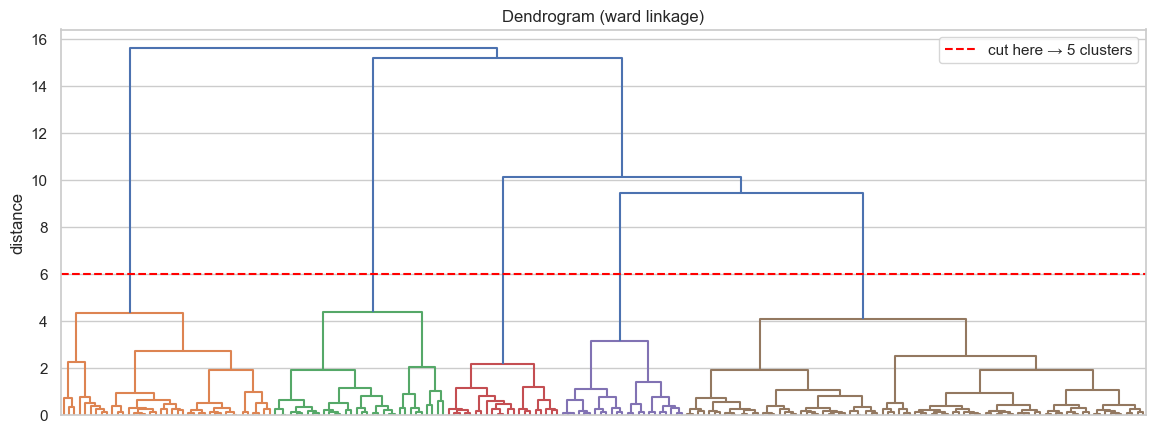

In [14]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=6)
plt.axhline(6, ls='--', c='red', label='cut here → 5 clusters')
plt.title('Dendrogram (ward linkage)'); plt.ylabel('distance'); plt.legend(); plt.show()

> **วิธีอ่าน:** แกนตั้งคือระยะที่กลุ่มถูกรวมกัน — หาช่วงที่ **เส้นแนวตั้งยาวที่สุดโดยไม่มีการรวมกลุ่มเกิดขึ้น** แล้วตัดในช่วงนั้น
> ช่วงระยะ ~4.4 ถึง ~9.5 ไม่มีการรวมกลุ่มเกิดขึ้น → ตัดที่ ≈ 6 (เส้นแดง) ตัดผ่านเส้นแนวตั้ง **5 เส้น → 5 กลุ่ม** ตรงกับ K-Means
> (ข้อควรระวัง: หากตัดที่ระดับ 4 จะได้ 8 กลุ่ม)

### 8.2 เทรนและเทียบกับ K-Means

In [15]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=5, linkage='ward').fit(X)
df['Hierarchical'] = agg.labels_
print(f"Silhouette = {silhouette_score(X, agg.labels_):.3f}   Davies-Bouldin = {davies_bouldin_score(X, agg.labels_):.3f}")

# หมายเลขกลุ่มของสองวิธีไม่จำเป็นต้องตรงกัน ดูว่าลูกค้าถูกจัดอยู่ด้วยกันแบบเดียวกันไหม
ct = pd.crosstab(df['KMeans'], df['Hierarchical'])
print(f"ลูกค้าที่ถูกจัดกลุ่มเหมือน K-Means: {ct.max(axis=1).sum()} / {len(df)} คน")
ct

Silhouette = 0.554   Davies-Bouldin = 0.578
ลูกค้าที่ถูกจัดกลุ่มเหมือน K-Means: 196 / 200 คน


Hierarchical,0,1,2,3,4
KMeans,,,,,
0,0,0,81,0,0
1,0,39,0,0,0
2,0,0,1,21,0
3,32,0,3,0,0
4,0,0,0,0,23


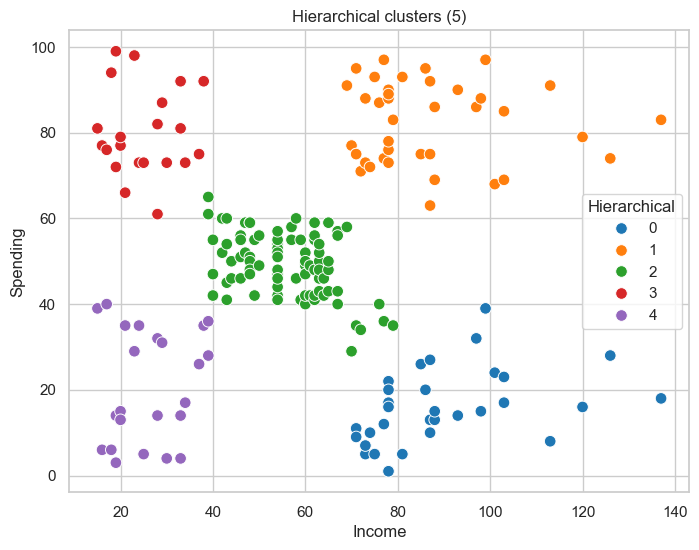

In [16]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Income', y='Spending', hue='Hierarchical', data=df, palette='tab10', s=70)
plt.title('Hierarchical clusters (5)'); plt.show()

### 8.3 การวิเคราะห์ผล Hierarchical

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| Dendrogram บอกกี่กลุ่ม? | ช่วงว่างยาวที่สุดอยู่ระหว่างระยะ ~4.4–9.5 → **5 กลุ่ม** | ยืนยัน k = 5 โดยไม่ต้องใช้ Elbow |
| คุณภาพกลุ่ม | Silhouette **0.554**, Davies-Bouldin **0.578** | แทบเท่า K-Means (0.555 / 0.572) |
| ได้กลุ่มเหมือน K-Means หรือไม่ | ตรงกัน **196 / 200 คน** (98%) | สองวิธีต่างหลักการแต่ได้คำตอบเดียวกัน → ผลน่าเชื่อถือ |
| 4 คนที่ต่างคือใคร? | ลูกค้าที่อยู่ **รอยต่อ** ระหว่างกลุ่มกลางกับกลุ่มข้างเคียง | เป็นลักษณะปกติของข้อมูลที่อยู่บริเวณขอบกลุ่ม |

> **สรุป:** ได้ผลเกือบเหมือน K-Means — ข้อดีคือมี Dendrogram ให้เห็นว่ากลุ่มไหนคล้ายกันและควรแบ่งกี่กลุ่ม

---
# ขั้นที่ 9: โมเดลที่ 3 — DBSCAN

### หลักการ
หากลุ่มจาก **ความหนาแน่น** — จุดที่มีเพื่อนบ้านอย่างน้อย `min_samples` ตัวในรัศมี `eps` คือแกนกลุ่ม
- **ไม่ต้องกำหนดจำนวนกลุ่ม** — ได้จำนวนกลุ่มเอง
- จุดที่ไม่อยู่ในกลุ่มใดจะถูกติดป้าย **`-1` = Noise (ค่าผิดปกติ)** ← ใช้หา Outlier ได้
- สามารถจับกลุ่มที่มีรูปร่างไม่เป็นทรงกลมได้ ซึ่งต่างจาก K-Means

### 9.1 เลือก `eps` ด้วย k-distance plot
เรียงระยะถึงเพื่อนบ้านลำดับที่ `min_samples` ของทุกจุด แล้วหา "ข้อศอก" ของกราฟ

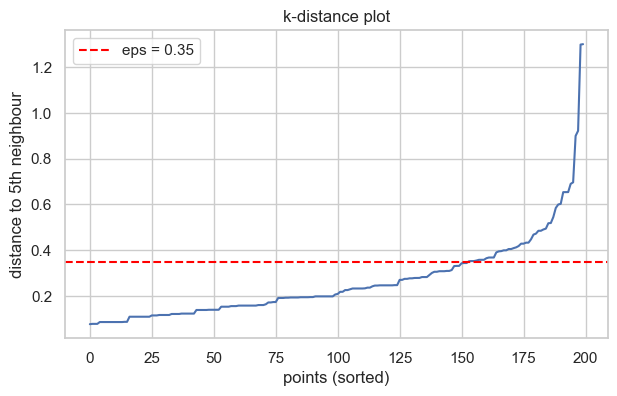

In [17]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

min_samples = 5
dist = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1]
plt.figure(figsize=(7, 4))
plt.plot(np.sort(dist))
plt.axhline(0.35, ls='--', c='red', label='eps = 0.35')
plt.xlabel('points (sorted)'); plt.ylabel(f'distance to {min_samples}th neighbour'); plt.title('k-distance plot')
plt.legend(); plt.show()

In [18]:
rows = []
for eps in [0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    mask = labels != -1
    sil = silhouette_score(X[mask], labels[mask]) if n_clusters > 1 else np.nan
    rows.append({'eps': eps, 'Clusters': n_clusters, 'Noise points': (labels == -1).sum(), 'Silhouette (no noise)': sil})
pd.DataFrame(rows).round(3)

,eps,Clusters,Noise points,Silhouette (no noise)
0,0.25,6,50,0.532
1,0.30,7,35,0.524
2,0.35,6,23,0.558
3,0.40,4,15,0.478
4,0.45,3,11,0.354
5,0.50,2,8,0.388


> **ข้อสังเกต:** กราฟ k-distance เริ่มชันขึ้นช่วง ~0.35–0.5 (ข้อศอก) / `eps` เล็ก → ได้จำนวนกลุ่มและ Noise มาก / `eps` ใหญ่ → กลุ่มรวมกันจนเหลือน้อย
> ค่า **0.35** สมดุลที่สุด (Silhouette สูงสุด, Noise ไม่มากเกินไป)

### 9.2 เทรนและดูผล

จำนวนกลุ่ม: 6   Noise: 23 คน
Silhouette (ไม่รวม Noise) = 0.558


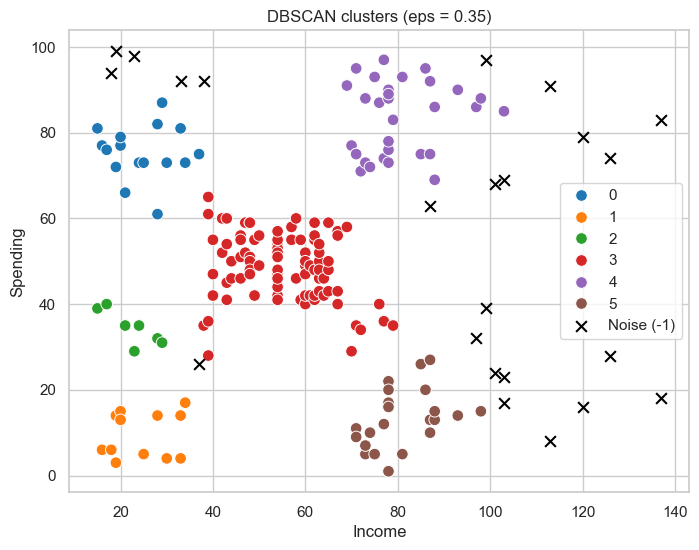

Income      Spending     
         mean size     mean size
DBSCAN                          
0        24.8   16     75.4   16
1        24.6   12      9.6   12
2        22.4    7     34.4    7
3        55.2   88     48.6   88
4        80.3   31     83.2   31
5        81.0   23     12.8   23

In [19]:
dbscan = DBSCAN(eps=0.35, min_samples=min_samples).fit(X)
df['DBSCAN'] = dbscan.labels_
mask = dbscan.labels_ != -1
print("จำนวนกลุ่ม:", len(set(dbscan.labels_)) - 1, "  Noise:", (~mask).sum(), "คน")
print(f"Silhouette (ไม่รวม Noise) = {silhouette_score(X[mask], dbscan.labels_[mask]):.3f}")

plt.figure(figsize=(8, 6))
sns.scatterplot(x='Income', y='Spending', hue='DBSCAN', data=df[mask], palette='tab10', s=70)
plt.scatter(df.loc[~mask, 'Income'], df.loc[~mask, 'Spending'], c='black', marker='x', s=60, label='Noise (-1)')
plt.title('DBSCAN clusters (eps = 0.35)'); plt.legend(); plt.show()

df[mask].groupby('DBSCAN')[['Income', 'Spending']].agg(['mean', 'size']).round(1)

### 9.3 การวิเคราะห์ผล DBSCAN

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ได้กี่กลุ่ม? | **6 กลุ่ม + Noise 23 คน** (11.5%) | ไม่ต้องกำหนดจำนวนกลุ่มเอง |
| ต่างจาก K-Means อย่างไร? | แยกกลุ่ม "รายได้ต่ำ" ออกเป็น 3 กลุ่มย่อย (ใช้จ่ายสูง 16, ต่ำ 12, ปานกลาง 7 คน) | กลุ่มรายได้ต่ำ-ใช้จ่ายปานกลางมีเพียง 7 คน อาจเล็กเกินไปที่จะทำการตลาดแยก |
| Noise คือใคร? | 13 จาก 23 คน มีรายได้ ≥ $100k (รายได้สูงสุดในห้าง) ที่เหลืออยู่ขอบกลุ่ม | ใช้หา **ลูกค้าผิดปกติ (Outlier)** ได้ — เช่นกลุ่มรายได้สูงมากที่อาจต้องดูแลพิเศษ |
| คุณภาพกลุ่ม | Silhouette **0.558**, Davies-Bouldin **0.511** | สูงที่สุด แต่ **คำนวณโดยตัด Noise ออก** (ไม่นับจุดที่จัดกลุ่มได้ยาก) → เทียบกับ K-Means ไม่ยุติธรรม |

> **สรุป:** DBSCAN เหมาะกับข้อมูลที่กลุ่มมีรูปร่างแปลก หรือต้องการหา Outlier
> ข้อมูลชุดนี้กลุ่มเป็นก้อนกลมชัดเจน K-Means จึงเหมาะกว่า แต่ DBSCAN ให้ข้อมูลเพิ่มเรื่อง **ลูกค้าที่ไม่เข้ากลุ่มใด**

---
# ขั้นที่ 10: เปรียบเทียบ 3 วิธี

In [20]:
def score_row(name, labels):
    m = labels != -1
    return {'Method': name, 'Clusters': len(set(labels[m])), 'Noise': int((~m).sum()),
            'Silhouette': silhouette_score(X[m], labels[m]), 'Davies-Bouldin': davies_bouldin_score(X[m], labels[m])}

compare = pd.DataFrame([score_row('K-Means (k=5)', kmeans.labels_),
                        score_row('Hierarchical (5)', agg.labels_),
                        score_row('DBSCAN (eps=0.35)', dbscan.labels_)]).set_index('Method').round(3)
compare

,Clusters,Noise,Silhouette,Davies-Bouldin
Method,,,,
K-Means (k=5),5,0,0.555,0.572
Hierarchical (5),5,0,0.554,0.578
DBSCAN (eps=0.35),6,23,0.558,0.511


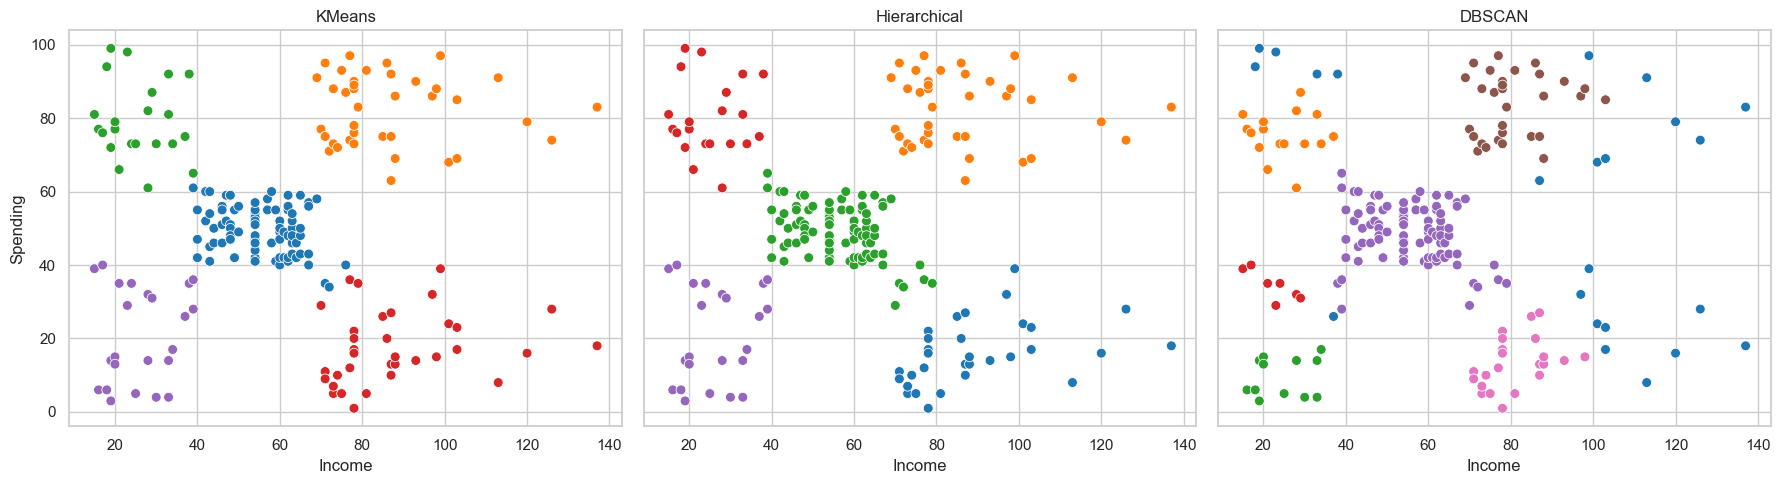

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, col in zip(axes, ['KMeans', 'Hierarchical', 'DBSCAN']):
    sns.scatterplot(x='Income', y='Spending', hue=col, data=df, palette='tab10', s=50, ax=ax, legend=False)
    ax.set_title(col)
plt.tight_layout(); plt.show()

### 10.1 การวิเคราะห์ผลการเปรียบเทียบ

| วิธี | กลุ่ม | Noise | Silhouette | Davies-Bouldin | ข้อดี | ข้อจำกัด |
|---|---|---|---|---|---|---|
| **K-Means** | 5 | 0 | 0.555 | 0.572 | เร็ว ง่าย มี Centroid ไว้ตีความ | ต้องเลือก k เอง, ชอบกลุ่มทรงกลม |
| Hierarchical | 5 | 0 | 0.554 | 0.578 | มี Dendrogram ช่วยเลือกจำนวนกลุ่ม | ช้าเมื่อข้อมูลใหญ่ |
| DBSCAN | 6 | 23 | 0.558* | 0.511* | หา Outlier ได้ ไม่ต้องกำหนด k | เลือก eps ยาก, *คะแนนไม่รวม Noise |

**ข้อสรุป**
1. K-Means และ Hierarchical **ได้กลุ่มเกือบเหมือนกัน (98%)** → กลุ่มลูกค้า 5 กลุ่มนี้ "มีอยู่จริง" ไม่ได้ขึ้นกับอัลกอริทึม
2. ค่า Silhouette ทั้งสามใกล้กันมาก (0.554–0.558) → ไม่สามารถตัดสินจากตัวเลขเพียงอย่างเดียวได้ ต้องดู **การใช้งานจริง**
3. **เลือก K-Means** เพราะลูกค้าทุกคนได้กลุ่ม (ไม่มี Noise) ทีมการตลาดใช้งานง่าย และ Centroid อธิบายแต่ละกลุ่มได้ทันที
4. ใช้ DBSCAN เสริมเพื่อดู **ลูกค้า 23 คนที่ผิดปกติ**

---
# ขั้นที่ 11 (เพิ่มเติม): ใช้ 3 Feature + PCA เพื่อวาดกราฟ

ถ้าใช้ `Age` + `Income` + `Spending` (3 มิติ) จะไม่สามารถแสดงเป็นกราฟ 2 มิติได้โดยตรง
→ ใช้ **PCA (Principal Component Analysis)** ย่อ 3 มิติเหลือ 2 มิติ โดยเก็บข้อมูล (ความแปรปรวน) ไว้มากที่สุด

Silhouette (3 Feature): {2: 0.335, 3: 0.358, 4: 0.404, 5: 0.417, 6: 0.428, 7: 0.417, 8: 0.408, 9: 0.418, 10: 0.407}
k ที่ดีที่สุด: 6
PCA เก็บความแปรปรวนได้: [0.443 0.333] รวม 0.776


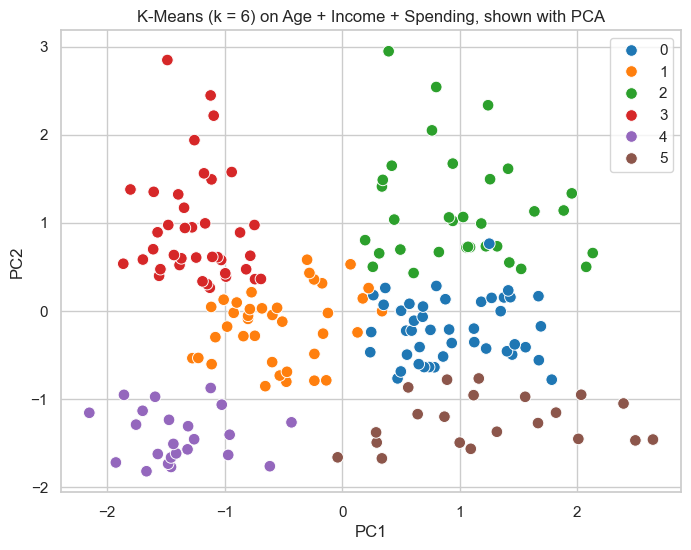

,Age,Income,Spending,Customers
KMeans3,,,,
0,56.3,54.3,49.1,45
1,26.8,57.1,48.1,39
2,41.9,88.9,17.0,33
3,32.7,86.5,82.1,39
4,25.0,25.3,77.6,23
5,45.5,26.3,19.4,21


In [22]:
from sklearn.decomposition import PCA

X3 = StandardScaler().fit_transform(df[['Age', 'Income', 'Spending']])
sil3 = {k: silhouette_score(X3, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X3)) for k in range(2, 11)}
best_k3 = max(sil3, key=sil3.get)
print("Silhouette (3 Feature):", {k: round(v, 3) for k, v in sil3.items()})
print("k ที่ดีที่สุด:", best_k3)

km3 = KMeans(n_clusters=best_k3, n_init=10, random_state=42).fit(X3)
pca = PCA(n_components=2).fit(X3)
X_pca = pca.transform(X3)
print("PCA เก็บความแปรปรวนได้:", pca.explained_variance_ratio_.round(3), "รวม", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=km3.labels_, palette='tab10', s=70)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title(f'K-Means (k = {best_k3}) on Age + Income + Spending, shown with PCA'); plt.show()

df.assign(KMeans3=km3.labels_).groupby('KMeans3')[['Age', 'Income', 'Spending']].mean().round(1).assign(Customers=pd.Series(km3.labels_).value_counts())

### 11.1 การวิเคราะห์ผล PCA + 3 Feature

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| k ที่ดีที่สุด | **k = 6** (Silhouette 0.428) | เพิ่ม Age แล้วได้กลุ่มเพิ่ม 1 กลุ่ม |
| คุณภาพกลุ่ม | Silhouette 0.428 < 0.555 (2 Feature) | กลุ่มแยกกันชัดน้อยลง — เพิ่ม Feature ไม่ได้ทำให้ดีขึ้นเสมอ |
| PCA เก็บข้อมูลได้เพียงใด? | PC1 44% + PC2 33% = **78%** | กราฟ 2 มิติแสดงข้อมูล 3 มิติได้ค่อนข้างครบ |
| กลุ่มที่เพิ่มมาคืออะไร? | กลุ่มกลาง (รายได้/ใช้จ่ายปานกลาง) ถูกแยกตามอายุ: **วัยทำงานตอนต้น ~27 ปี** กับ **วัยกลางคน ~56 ปี** | Age ช่วยแยกกลุ่มกลางที่ใหญ่ที่สุดให้ละเอียดขึ้น |

> **สรุป:** ถ้าทีมการตลาดอยากทำแคมเปญแยกตามวัยสำหรับกลุ่มกลาง ใช้แบบ 3 Feature (6 กลุ่ม)
> ถ้าต้องการกลุ่มที่ชัดและง่าย ใช้แบบ 2 Feature (5 กลุ่ม)

---
# ขั้นที่ 12: Persona และข้อเสนอแนะทางธุรกิจ

ตั้งชื่อกลุ่มจาก **ค่าเฉลี่ยรายได้และการใช้จ่าย** ของแต่ละกลุ่ม (ใช้โค้ดตั้งชื่อ เพราะหมายเลขกลุ่มอาจสลับเมื่อรันบนเครื่อง/เวอร์ชันอื่น)

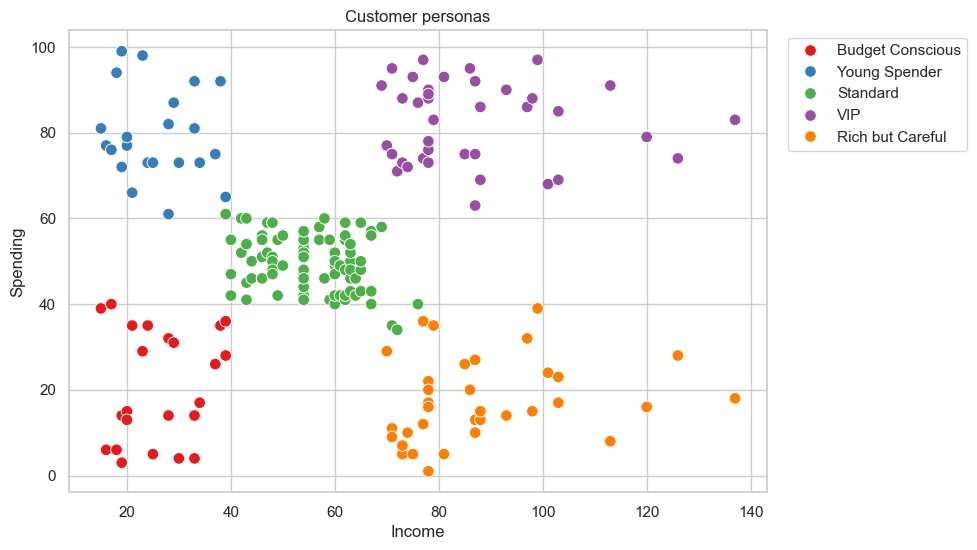

,Customers,Age,Income,Spending
Persona,,,,
Young Spender,22,25.3,25.7,79.4
Budget Conscious,23,45.2,26.3,20.9
Standard,81,42.7,55.3,49.5
VIP,39,32.7,86.5,82.1
Rich but Careful,35,41.1,88.2,17.1


In [23]:
def level(value, low, high):
    return 'Low' if value < low else ('High' if value > high else 'Mid')

persona_names = {('High', 'High'): 'VIP',          ('High', 'Low'): 'Rich but Careful',
                 ('Mid', 'Mid'):   'Standard',     ('Low', 'High'): 'Young Spender',
                 ('Low', 'Low'):   'Budget Conscious'}

centers_df = df.groupby('KMeans')[['Income', 'Spending']].mean()
persona_map = {c: persona_names.get((level(r.Income, 40, 70), level(r.Spending, 40, 60)), 'Other')
               for c, r in centers_df.iterrows()}
df['Persona'] = df['KMeans'].map(persona_map)

plt.figure(figsize=(9, 6))
sns.scatterplot(x='Income', y='Spending', hue='Persona', data=df, palette='Set1', s=70)
plt.title('Customer personas'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.show()

df.groupby('Persona').agg(Customers=('Age', 'size'), Age=('Age', 'mean'), Income=('Income', 'mean'),
                          Spending=('Spending', 'mean')).round(1).sort_values('Income')

### 12.1 Persona และข้อเสนอแนะ

| Persona | จำนวน | ลักษณะ | ข้อเสนอแนะทางการตลาด |
|---|---|---|---|
| **VIP** | 39 (20%) | รายได้สูง (~$87k) ใช้จ่ายสูง (~82) อายุ ~33 | **กลุ่มเป้าหมายหลัก** — โปรแกรมสมาชิก/สิทธิพิเศษ สินค้าพรีเมียม รักษาไว้ให้ได้ |
| **Rich but Careful** | 35 (18%) | รายได้สูง (~$88k) แต่ใช้จ่ายต่ำ (~17) อายุ ~41 | **โอกาสเติบโตสูงสุด** — มีกำลังซื้อแต่ยังไม่ใช้จ่าย → สื่อสารเรื่องคุณภาพ/ความคุ้มค่า ข้อเสนอเฉพาะบุคคล |
| **Standard** | 81 (40%) | รายได้/ใช้จ่ายปานกลาง อายุ ~43 | กลุ่มใหญ่ที่สุด — โปรโมชันทั่วไป แต้มสะสม (แยกย่อยตามวัยได้ ดูขั้นที่ 11) |
| **Young Spender** | 22 (11%) | รายได้ต่ำ (~$26k) แต่ใช้จ่ายสูง (~79) อายุ ~25 | สินค้าแฟชั่น/เทรนด์ ผ่อนชำระ โปรโมชันนักศึกษา (ระวังความเสี่ยงด้านเครดิต) |
| **Budget Conscious** | 23 (12%) | รายได้ต่ำ (~$26k) ใช้จ่ายต่ำ (~21) อายุ ~45 | ส่วนลด สินค้าราคาประหยัด แพ็กคุ้มค่า — ไม่ควรลงงบการตลาดมาก |

> **ตัวอย่างการเขียนสรุปผลในข้อสอบ:**
> *"แบ่งลูกค้าได้ 5 กลุ่มด้วย K-Means (เลือก k = 5 จาก Elbow, Silhouette = 0.555 และ Davies-Bouldin = 0.572 ซึ่งดีที่สุด)
> ผลตรงกับ Hierarchical Clustering 98% กลุ่มที่ควรให้ความสำคัญคือ VIP (รายได้สูง-ใช้จ่ายสูง, 20%) เพื่อรักษาไว้
> และ Rich but Careful (รายได้สูง-ใช้จ่ายต่ำ, 18%) ซึ่งมีโอกาสเพิ่มยอดขายมากที่สุด"*

---
## รายการตรวจสอบ (Checklist): Clustering
- [ ] ลบคอลัมน์ ID / คอลัมน์ที่ไม่เกี่ยวกับพฤติกรรม
- [ ] **Scale ก่อนเสมอ** (ทุกวิธีใช้ระยะทาง)
- [ ] เลือก k ด้วย Elbow + Silhouette (+ Davies-Bouldin) อย่างน้อย 2 วิธี
- [ ] ทดลองอย่างน้อย 2 อัลกอริทึม แล้วเทียบ Silhouette / Davies-Bouldin
- [ ] DBSCAN: เลือก `eps` จาก k-distance plot, รายงานจำนวน Noise
- [ ] ข้อมูลเกิน 2 มิติ → ใช้ PCA ช่วยวาดกราฟ
- [ ] **ตีความแต่ละกลุ่ม** (Profile → ตั้งชื่อ Persona → ข้อเสนอแนะ) — ตัวเลขเพียงอย่างเดียวไม่เพียงพอ

## แบบฝึกหัด
1. ทดลองจัดกลุ่มด้วย `Age` + `Spending` (แบบในต้นฉบับ Kaggle) — k ที่ดีที่สุดคือเท่าใด Persona ต่างจากเดิมอย่างไร?
2. ทดลอง `AgglomerativeClustering` ด้วย `linkage='average'` และ `'complete'` แล้วเทียบ Silhouette กับ `'ward'`

In [24]:
# เฉลยข้อ 1
X_as = StandardScaler().fit_transform(df[['Age', 'Spending']])
sil_as = {k: silhouette_score(X_as, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_as)) for k in range(2, 9)}
print({k: round(v, 3) for k, v in sil_as.items()})
k_as = max(sil_as, key=sil_as.get)
labels_as = KMeans(n_clusters=k_as, n_init=10, random_state=42).fit_predict(X_as)
df.assign(Cluster=labels_as).groupby('Cluster')[['Age', 'Income', 'Spending']].mean().round(1)

{2: 0.472, 3: 0.44, 4: 0.438, 5: 0.448, 6: 0.457, 7: 0.411, 8: 0.405}


,Age,Income,Spending
Cluster,,,
0,48.7,60.5,32.2
1,28.4,60.6,69.3
